# Task 3: CycleGAN Monet ↔ Photo (Kaggle class competition)

A CycleGAN built from scratch (2 ResNet generators, 2 PatchGAN discriminators), trained with adversarial,
cycle-consistency and identity losses. No pretrained models are used to generate images; the pretrained
Inception-v3 / AlexNet networks are used **only to measure** (FID, KID, LPIPS).

**How to run (only this one file is needed):**
1. One-time: in Colab click the 🔑 **Secrets** icon (left sidebar), add `KAGGLE_API_TOKEN` with your Kaggle token, and enable notebook access.
2. Runtime → Change runtime type → choose a **GPU** (A100 recommended).
3. Runtime → Run all.

Everything is saved in Google Drive under `MyDrive/DATA266_task3/`. If Colab disconnects, just Run all again:
training resumes from the last checkpoint.

## 1. GPU

In [1]:
!nvidia-smi

Sun Oct  4 02:48:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   39C    P0             54W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 2. Working folder in Google Drive

In [2]:
import os
from google.colab import drive
drive.mount('/content/drive')

WORK = "/content/drive/MyDrive/DATA266_task3"  # same folder layout as the GitHub repo
os.makedirs(f"{WORK}/task3_gan/scripts", exist_ok=True)
os.makedirs(f"{WORK}/task3_gan/kruthika/src", exist_ok=True)
%cd "{WORK}"

Mounted at /content/drive
/content/drive/MyDrive/DATA266_task3


## 3. Install packages and Kaggle access

In [3]:
!pip install -q pyyaml kaggle lpips
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")  # never printed or saved

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 3.6 MB/s eta 0:00:00


## 4. Code
Each cell writes one file of the repo (identical to the GitHub version).

### Dataset download (Kaggle)
`task3_gan/scripts/download_kaggle_data.py`

In [4]:
%%writefile task3_gan/scripts/download_kaggle_data.py
"""Download the class Kaggle competition data into task3_gan/data/.

Result:
    task3_gan/data/monet_jpg/    300 Monet paintings (256x256 RGB JPG)
    task3_gan/data/photo_jpg/    7,038 photos (256x256 RGB JPG)
    task3_gan/data/real_stats.npz  Inception statistics of the 300 Monets shipped with the competition
                                   (not used by the evaluation script, which recomputes features)

Needs a Kaggle API token (Kaggle -> Settings -> API -> Create New Token):
either the KAGGLE_API_TOKEN environment variable (e.g. from Colab Secrets) or ~/.kaggle/access_token.
You must have joined the competition on its Kaggle page.

Usage (from the repo root):
    python task3_gan/scripts/download_kaggle_data.py
"""
import shutil
import subprocess
import sys
import zipfile
from pathlib import Path

COMPETITION = "data-266-fall-2026-gan-image-style-transfer"

current_file = Path(__file__).resolve()
task3 = current_file.parent.parent
data_folder = task3 / "data"


def download_kaggle_data():
    """Download and arrange the data if it is not there yet; return the data folder."""
    if (data_folder / "monet_jpg").is_dir() and (data_folder / "photo_jpg").is_dir() \
            and (data_folder / "real_stats.npz").exists():
        print("Dataset already exists.")
        return data_folder
    data_folder.mkdir(parents=True, exist_ok=True)
    kaggle = shutil.which("kaggle") or str(Path(sys.executable).parent / "kaggle")
    subprocess.run([kaggle, "competitions", "download", "-c", COMPETITION, "-p", str(data_folder)], check=True)
    zip_path = data_folder / f"{COMPETITION}.zip"
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(data_folder)
    zip_path.unlink()
    # The zip nests the images under dataset/dataset/; move them to the layout the brief uses.
    nested = data_folder / "dataset" / "dataset"
    for name in ("monet_jpg", "photo_jpg"):
        if (nested / name).is_dir():
            shutil.move(str(nested / name), str(data_folder / name))
    shutil.rmtree(data_folder / "dataset", ignore_errors=True)
    for name in ("monet_jpg", "photo_jpg"):
        print(f"  {name}: {len(list((data_folder / name).glob('*.jpg'))):,} images")
    return data_folder


if __name__ == "__main__":
    download_kaggle_data()

Overwriting task3_gan/scripts/download_kaggle_data.py


### Config: model, training and evaluation settings
`task3_gan/kruthika/src/config.yaml`

In [5]:
%%writefile task3_gan/kruthika/src/config.yaml
# Task 3: CycleGAN Monet <-> Photo. All paths are relative to the repo root.
# Domain A = Monet paintings, domain B = photos (as in the competition).
# G_AB: Monet -> photo (pred_A2B), G_BA: photo -> Monet (pred_B2A).
# The evaluation script scores BOTH directions and reports their average FID and MiFID.

run_name: cyclegan_v1
seed: 42
device: auto

data:
  data_dir: task3_gan/data        # monet_jpg/, photo_jpg/ (download_kaggle_data.py)

model:
  ngf: 64                         # generator base width
  n_blocks: 9                     # residual blocks (9 = paper setting for 256x256)
  ndf: 64                         # discriminator base width
  n_layers: 3                     # 3 -> 70x70 PatchGAN

train:
  epochs: 60                      # 1 epoch = one pass over the 7,038 photos
  decay_start: 0.5                # constant LR for the first half, then linear decay to 0
  batch_size: 4
  lr_g: 2.0e-4
  lr_d: 2.0e-4
  betas: [0.5, 0.999]
  lambda_cycle: 10.0              # weight of cycle-consistency loss (paper: 10)
  lambda_identity: 0.5            # identity loss weight, as a fraction of lambda_cycle (paper: 0.5)
  pool_size: 50                   # history of generated images shown to D
  diffaug: "color,translation,cutout"   # augmentation of D inputs (real and fake); "" = off
  jitter: true                    # random flip + 286->256 crop on training images
  ema_decay: 0.999                # exponential moving average of generator weights
  precision: bf16                 # mixed precision on supported GPUs, fp32 otherwise
  log_every: 100                  # iterations between log lines
  eval_every: 2                   # epochs between competition-score checks (both directions, 600 images)
  ckpt_every: 2                   # epochs between resume checkpoints

eval:
  kid_subsets: 100
  prdc_k: 5
  lpips_photos: 1000              # photos used for LPIPS / cycle metrics (all 300 Monets are used)
  audit_samples: 30               # fixed samples for the blinded human audit
  jpg_quality: 95

Overwriting task3_gan/kruthika/src/config.yaml


### Config v2: fine-tune of v1 (lower identity weight, fresh LR schedule)
`task3_gan/kruthika/src/config_v2.yaml`

In [6]:
%%writefile task3_gan/kruthika/src/config_v2.yaml
# Task 3 v2: fine-tune of cyclegan_v1 (same architecture), lower identity weight and fresh LR schedule.
# All paths are relative to the repo root.
# Domain A = Monet paintings, domain B = photos (as in the competition).
# G_AB: Monet -> photo (pred_A2B), G_BA: photo -> Monet (pred_B2A).
# The evaluation script scores BOTH directions and reports their average FID and MiFID.

run_name: cyclegan_v2_ft
seed: 42
device: auto

data:
  data_dir: task3_gan/data        # monet_jpg/, photo_jpg/ (download_kaggle_data.py)

model:
  ngf: 64                         # generator base width
  n_blocks: 9                     # residual blocks (9 = paper setting for 256x256)
  ndf: 64                         # discriminator base width
  n_layers: 3                     # 3 -> 70x70 PatchGAN

train:
  init_from: task3_gan/kruthika/checkpoints/cyclegan_v1_last.pt   # start from v1's final weights
  epochs: 30                      # fine-tuning epochs on top of v1 (1 epoch = 7,038 photos)
  decay_start: 0.33               # constant LR for the first third, then linear decay to 0
  batch_size: 4
  lr_g: 1.0e-4                    # half of v1: the model is already trained
  lr_d: 1.0e-4
  betas: [0.5, 0.999]
  lambda_cycle: 10.0              # weight of cycle-consistency loss (paper: 10)
  lambda_identity: 0.1            # v1: 0.5. Weaker pull towards the input -> stronger style
  pool_size: 50                   # history of generated images shown to D
  diffaug: "color,translation,cutout"   # augmentation of D inputs (real and fake); "" = off
  jitter: true                    # random flip + 286->256 crop on training images
  ema_decay: 0.999                # exponential moving average of generator weights
  precision: bf16                 # mixed precision on supported GPUs, fp32 otherwise
  log_every: 100                  # iterations between log lines
  eval_every: 2                   # epochs between competition-score checks (both directions, 600 images)
  ckpt_every: 2                   # epochs between resume checkpoints

eval:
  kid_subsets: 100
  prdc_k: 5
  lpips_photos: 1000              # photos used for LPIPS / cycle metrics (all 300 Monets are used)
  audit_samples: 30               # fixed samples for the blinded human audit
  jpg_quality: 95

Writing task3_gan/kruthika/src/config_v2.yaml


### Data loading, augmentation, DiffAugment
`task3_gan/kruthika/src/data.py`

In [7]:
%%writefile task3_gan/kruthika/src/data.py
"""Task 3.1 - the two unpaired domains (A = Monet, B = photo) and augmentation.

All images are loaded once as uint8 tensors (300 + 7,038 images, ~1.4 GB) and kept on the
GPU, so a training batch is just random indexing - no data-loader bottleneck.
"""
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image


def list_images(folder):
    return sorted(Path(folder).glob("*.jpg"))


def load_images(folder):
    """-> (uint8 tensor [N, 3, 256, 256], list of file names), in sorted file-name order."""
    files = list_images(folder)
    arr = np.stack([np.asarray(Image.open(f).convert("RGB")) for f in files])
    return torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous(), [f.name for f in files]


def to_float(x_uint8):
    """uint8 [0, 255] -> float [-1, 1]."""
    return x_uint8.float().div_(127.5).sub_(1.0)


def to_uint8(x):
    """float [-1, 1] -> uint8 [0, 255]."""
    return ((x.clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8)


def sample_batch(images, batch_size, jitter=True):
    """Random batch with the CycleGAN paper's jitter: random horizontal flip and a random
    256x256 crop from the image upscaled to 286x286."""
    idx = torch.randint(0, images.shape[0], (batch_size,), device=images.device)
    x = to_float(images[idx])
    if jitter:
        flip = torch.rand(batch_size, device=x.device) < 0.5
        x = torch.where(flip[:, None, None, None], x.flip(3), x)
        x = F.interpolate(x, size=286, mode="bilinear", align_corners=False)
        i, j = np.random.randint(0, 286 - 256 + 1, size=2)
        x = x[:, :, i:i + 256, j:j + 256]
    return x


# ---------------- DiffAugment (Zhao et al., 2020) ----------------
# Applied to BOTH real and fake images right before the discriminator, so the discriminator
# cannot memorise the 300 Monets; gradients still flow to the generator. Never applied to
# the images we submit.
def _color(x):
    x = x + (torch.rand(x.size(0), 1, 1, 1, device=x.device) - 0.5)                       # brightness
    m = x.mean(dim=1, keepdim=True)
    x = (x - m) * (torch.rand(x.size(0), 1, 1, 1, device=x.device) * 2) + m                # saturation
    m = x.mean(dim=[1, 2, 3], keepdim=True)
    x = (x - m) * (torch.rand(x.size(0), 1, 1, 1, device=x.device) + 0.5) + m              # contrast
    return x


def _translation(x, ratio=0.125):
    B, _, H, W = x.shape
    sx, sy = int(H * ratio + 0.5), int(W * ratio + 0.5)
    tx = torch.randint(-sx, sx + 1, (B, 1, 1), device=x.device)
    ty = torch.randint(-sy, sy + 1, (B, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=x.device), torch.arange(H, device=x.device),
                                torch.arange(W, device=x.device), indexing="ij")
    gx = torch.clamp(gx + tx + 1, 0, H + 1)
    gy = torch.clamp(gy + ty + 1, 0, W + 1)
    padded = F.pad(x, [1, 1, 1, 1, 0, 0, 0, 0])
    return padded.permute(0, 2, 3, 1).contiguous()[gb, gx, gy].permute(0, 3, 1, 2)


def _cutout(x, ratio=0.5):
    B, _, H, W = x.shape
    ch, cw = int(H * ratio + 0.5), int(W * ratio + 0.5)
    ox = torch.randint(0, H + (1 - ch % 2), (B, 1, 1), device=x.device)
    oy = torch.randint(0, W + (1 - cw % 2), (B, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=x.device), torch.arange(ch, device=x.device),
                                torch.arange(cw, device=x.device), indexing="ij")
    gx = torch.clamp(gx + ox - ch // 2, 0, H - 1)
    gy = torch.clamp(gy + oy - cw // 2, 0, W - 1)
    mask = torch.ones(B, H, W, dtype=x.dtype, device=x.device)
    mask[gb, gx, gy] = 0
    return x * mask.unsqueeze(1)


_POLICY = {"color": _color, "translation": _translation, "cutout": _cutout}


def diff_augment(x, policy):
    """policy: e.g. 'color,translation,cutout'; empty string = no augmentation."""
    for p in [p for p in policy.split(",") if p]:
        x = _POLICY[p](x)
    return x

Overwriting task3_gan/kruthika/src/data.py


### Task 3.1: generators and discriminators
`task3_gan/kruthika/src/models.py`

In [8]:
%%writefile task3_gan/kruthika/src/models.py
"""Task 3.1 - CycleGAN networks, written from scratch (Zhu et al., 2017).

Generator: ResNet encoder-decoder (c7s1-64, d128, d256, n x R256, u128, u64, c7s1-3).
Discriminator: 70x70 PatchGAN - classifies overlapping 70x70 patches as real/fake,
which focuses it on local texture (brush strokes) rather than global layout.
Images are in [-1, 1].
"""
import torch
import torch.nn as nn


class ResidualBlock(nn.Module):
    """x + F(x): lets the generator keep the photo's structure and only learn the change."""

    def __init__(self, ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.ReflectionPad2d(1), nn.Conv2d(ch, ch, 3), nn.InstanceNorm2d(ch), nn.ReLU(True),
            nn.ReflectionPad2d(1), nn.Conv2d(ch, ch, 3), nn.InstanceNorm2d(ch),
        )

    def forward(self, x):
        return x + self.block(x)


class Generator(nn.Module):
    def __init__(self, ngf=64, n_blocks=9, **_):
        super().__init__()
        layers = [nn.ReflectionPad2d(3), nn.Conv2d(3, ngf, 7), nn.InstanceNorm2d(ngf), nn.ReLU(True)]
        ch = ngf
        for _ in range(2):  # downsample 256 -> 64
            layers += [nn.Conv2d(ch, ch * 2, 3, stride=2, padding=1), nn.InstanceNorm2d(ch * 2), nn.ReLU(True)]
            ch *= 2
        layers += [ResidualBlock(ch) for _ in range(n_blocks)]
        for _ in range(2):  # upsample 64 -> 256
            layers += [nn.ConvTranspose2d(ch, ch // 2, 3, stride=2, padding=1, output_padding=1),
                       nn.InstanceNorm2d(ch // 2), nn.ReLU(True)]
            ch //= 2
        layers += [nn.ReflectionPad2d(3), nn.Conv2d(ch, 3, 7), nn.Tanh()]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class Discriminator(nn.Module):
    """PatchGAN: outputs a 30x30 map of real/fake scores for a 256x256 image."""

    def __init__(self, ndf=64, n_layers=3, **_):
        super().__init__()
        layers = [nn.Conv2d(3, ndf, 4, stride=2, padding=1), nn.LeakyReLU(0.2, True)]
        ch = ndf
        for i in range(1, n_layers + 1):
            nxt = ndf * min(2 ** i, 8)
            stride = 2 if i < n_layers else 1
            layers += [nn.Conv2d(ch, nxt, 4, stride=stride, padding=1), nn.InstanceNorm2d(nxt), nn.LeakyReLU(0.2, True)]
            ch = nxt
        layers += [nn.Conv2d(ch, 1, 4, stride=1, padding=1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def init_weights(m):
    """N(0, 0.02) init as in the CycleGAN paper."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)


class ImagePool:
    """History of generated images (Shrivastava et al.): the discriminator sees a mix of current
    and older fakes, which reduces oscillation between G and D."""

    def __init__(self, size=50):
        self.size, self.images = size, []

    def query(self, images):
        if self.size == 0:
            return images
        out = []
        for img in images.detach():
            img = img.unsqueeze(0)
            if len(self.images) < self.size:
                self.images.append(img)
                out.append(img)
            elif torch.rand(1).item() < 0.5:
                i = torch.randint(0, self.size, (1,)).item()
                out.append(self.images[i].clone())
                self.images[i] = img
            else:
                out.append(img)
        return torch.cat(out)


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

Overwriting task3_gan/kruthika/src/models.py


### Metrics: competition FID/MiFID, KID, PRDC, LPIPS, kappa
`task3_gan/kruthika/src/metrics.py`

In [9]:
%%writefile task3_gan/kruthika/src/metrics.py
"""Task 3 evaluation metrics.

The competition score follows the instructor's evaluation script (Part3_Evaluation_Script.ipynb):
- Inception-v3 (torchvision IMAGENET1K_V1, transform_input=False), 2048-d pool features;
  images go through PIL Resize(299) -> CenterCrop(299) -> ToTensor -> ImageNet normalisation.
- Only the first N_EVAL = 300 files (sorted by name) of each folder are used.
- FID between real and generated features; "MiFID" = mean cosine distance between real[i] and
  generated[i], paired by index.
- Done for both directions (photo->Monet vs real Monets, Monet->photo vs real photos), and the
  submission reports the AVERAGE FID and AVERAGE MiFID of the two directions.
`official_features` reproduces that pipeline exactly (used for submission.csv);
`InceptionFeatures.__call__` is a fast GPU version for scoring during training (cosine 0.9998 with it).
Pretrained networks are used here ONLY to measure images, never to generate them.
"""
import io

import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from scipy import linalg

N_EVAL = 300
_MEAN = (0.485, 0.456, 0.406)
_STD = (0.229, 0.224, 0.225)


class InceptionFeatures:
    def __init__(self, device):
        import torchvision
        self.model = torchvision.models.inception_v3(
            weights=torchvision.models.Inception_V3_Weights.IMAGENET1K_V1, transform_input=False)
        self.model.fc = torch.nn.Identity()
        self.model.eval().to(device)
        self.device = device
        self.mean = torch.tensor(_MEAN, device=device).view(1, 3, 1, 1)
        self.std = torch.tensor(_STD, device=device).view(1, 3, 1, 1)

    @torch.no_grad()
    def __call__(self, images_uint8, batch_size=100):
        """Fast path: uint8 [N, 3, 256, 256] -> float32 numpy [N, 2048]."""
        out = []
        for i in range(0, len(images_uint8), batch_size):
            x = images_uint8[i:i + batch_size].to(self.device).float() / 255.0
            x = F.interpolate(x, size=(299, 299), mode="bilinear", align_corners=False)
            out.append(self.model((x - self.mean) / self.std).float().cpu())
        return torch.cat(out).numpy()

    @torch.no_grad()
    def official_features(self, paths, batch_size=32):
        """Exactly the evaluation script's pipeline, on image files."""
        import torchvision.transforms as T
        tf = T.Compose([T.Resize(299), T.CenterCrop(299), T.ToTensor(), T.Normalize(_MEAN, _STD)])
        feats = []
        for i in range(0, len(paths), batch_size):
            x = torch.stack([tf(Image.open(p).convert("RGB")) for p in paths[i:i + batch_size]]).to(self.device)
            feats.append(self.model(x).detach().cpu().numpy())
        return np.concatenate(feats, axis=0)


def jpeg_roundtrip(images_uint8, quality):
    """Encode/decode as JPEG in memory, so in-training scores see the same compression as the files."""
    out = []
    for img in images_uint8.cpu():
        buf = io.BytesIO()
        Image.fromarray(img.permute(1, 2, 0).numpy()).save(buf, format="JPEG", quality=quality)
        out.append(torch.from_numpy(np.asarray(Image.open(buf).convert("RGB"))).permute(2, 0, 1))
    return torch.stack(out)


# ---------------- competition metrics (as in the evaluation script) ----------------
def gaussian_stats(feats):
    return feats.mean(0), np.cov(feats, rowvar=False)


def fid(mu1, s1, mu2, s2, eps=1e-6):
    """Same maths as the script's frechet_distance; works with old and new scipy versions
    (scipy >= 1.18 removed the `disp` argument the script passes to sqrtm)."""
    covmean = linalg.sqrtm(s1.dot(s2))
    if isinstance(covmean, tuple):
        covmean = covmean[0]
    if not np.isfinite(covmean).all():
        offset = np.eye(s1.shape[0]) * eps
        covmean = linalg.sqrtm((s1 + offset).dot(s2 + offset))
        if isinstance(covmean, tuple):
            covmean = covmean[0]
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    diff = mu1 - mu2
    return float(diff.dot(diff) + np.trace(s1 + s2 - 2 * covmean))


def fid_mifid(real_feats, gen_feats):
    """One direction, as calculate_fid_mifid in the script: match counts by taking the first n,
    FID of the two sets, MiFID = mean cosine distance of real[i] vs gen[i]."""
    n = min(len(real_feats), len(gen_feats))
    r, g = real_feats[:n].astype(np.float64), gen_feats[:n].astype(np.float64)
    f = fid(*gaussian_stats(r), *gaussian_stats(g))
    cos = (r * g).sum(1) / (np.linalg.norm(r, axis=1) * np.linalg.norm(g, axis=1))
    return f, float((1 - cos).mean())


def competition_score(real_monet_f, real_photo_f, gen_b2a_f, gen_a2b_f):
    """Both directions + submission values (average FID, average MiFID) + estimated leaderboard score."""
    fid_b2a, mifid_b2a = fid_mifid(real_monet_f[:N_EVAL], gen_b2a_f[:N_EVAL])
    fid_a2b, mifid_a2b = fid_mifid(real_photo_f[:N_EVAL], gen_a2b_f[:N_EVAL])
    sub_fid, sub_mifid = (fid_a2b + fid_b2a) / 2, (mifid_a2b + mifid_b2a) / 2
    return {"fid_B2A": fid_b2a, "mifid_B2A": mifid_b2a, "fid_A2B": fid_a2b, "mifid_A2B": mifid_a2b,
            "FID": sub_fid, "MiFID": sub_mifid, "score": (sub_fid + sub_mifid) / 2}


def _cos_dist(a, b):
    a = a / np.linalg.norm(a, axis=1, keepdims=True)
    b = b / np.linalg.norm(b, axis=1, keepdims=True)
    return 1.0 - a @ b.T


# ---------------- additional metrics (brief) ----------------
def kid(feats_gen, feats_real, n_subsets=100, subset_size=1000, seed=0):
    """Kernel Inception Distance: unbiased MMD^2 with a cubic polynomial kernel, mean and std over subsets."""
    rng = np.random.default_rng(seed)
    m = min(subset_size, len(feats_gen), len(feats_real))
    d = feats_gen.shape[1]
    vals = []
    for _ in range(n_subsets):
        x = feats_gen[rng.choice(len(feats_gen), m, replace=False)].astype(np.float64)
        y = feats_real[rng.choice(len(feats_real), m, replace=False)].astype(np.float64)
        kxx = (x @ x.T / d + 1) ** 3
        kyy = (y @ y.T / d + 1) ** 3
        kxy = (x @ y.T / d + 1) ** 3
        vals.append((kxx.sum() - np.trace(kxx)) / (m * (m - 1)) + (kyy.sum() - np.trace(kyy)) / (m * (m - 1))
                    - 2 * kxy.mean())
    return float(np.mean(vals)), float(np.std(vals))


def prdc(feats_real, feats_gen, k=5, max_n=3000, seed=0):
    """Precision, recall, density, coverage (Naeem et al., 2020) with k-NN balls in feature space."""
    rng = np.random.default_rng(seed)
    if len(feats_real) > max_n:
        feats_real = feats_real[rng.choice(len(feats_real), max_n, replace=False)]
    if len(feats_gen) > max_n:
        feats_gen = feats_gen[rng.choice(len(feats_gen), max_n, replace=False)]
    r, g = torch.from_numpy(feats_real).float(), torch.from_numpy(feats_gen).float()
    d_rr, d_gg, d_rg = torch.cdist(r, r), torch.cdist(g, g), torch.cdist(r, g)
    rad_r = d_rr.kthvalue(k + 1, dim=1).values  # +1 skips the point itself
    rad_g = d_gg.kthvalue(k + 1, dim=1).values
    inside = d_rg < rad_r[:, None]                # [real, gen]: gen inside real's ball
    return {
        "precision": inside.any(0).float().mean().item(),
        "recall": (d_rg < rad_g[None, :]).any(1).float().mean().item(),
        "density": (inside.sum(0).float() / k).mean().item(),
        "coverage": (d_rg.min(1).values < rad_r).float().mean().item(),
    }


def content_cosine(feats_in, feats_out):
    """Mean cosine similarity between Inception features of each input and its translation."""
    return float(1.0 - np.diag(_cos_dist(feats_in, feats_out)).mean())


class LPIPS:
    def __init__(self, device):
        import lpips
        self.model = lpips.LPIPS(net="alex", verbose=False).to(device).eval()
        self.device = device

    @torch.no_grad()
    def __call__(self, a_uint8, b_uint8, batch_size=50):
        vals = []
        for i in range(0, len(a_uint8), batch_size):
            a = a_uint8[i:i + batch_size].to(self.device).float() / 127.5 - 1
            b = b_uint8[i:i + batch_size].to(self.device).float() / 127.5 - 1
            vals.append(self.model(a, b).flatten().cpu())
        return float(torch.cat(vals).mean())


def cohen_kappa(r1, r2):
    """Agreement between two raters beyond chance (labels can be any hashable values)."""
    r1, r2 = np.asarray(r1), np.asarray(r2)
    labels = np.unique(np.concatenate([r1, r2]))
    po = (r1 == r2).mean()
    pe = sum((r1 == c).mean() * (r2 == c).mean() for c in labels)
    return float((po - pe) / (1 - pe)) if pe < 1 else 1.0

Overwriting task3_gan/kruthika/src/metrics.py


### Logging, manifests, device
`task3_gan/kruthika/src/utils.py`

In [10]:
%%writefile task3_gan/kruthika/src/utils.py
"""Run plumbing: config loading, seeding, device selection, raw logs and manifests.

All paths are resolved relative to the repo root so nothing personal is hard-coded.
"""
import hashlib
import json
import logging
import platform
import random
import subprocess
import sys
from datetime import datetime
from importlib import metadata
from pathlib import Path

import numpy as np
import torch
import yaml

REPO_ROOT = Path(__file__).resolve().parents[3]
MEMBER = "kruthika"
TASK = "task3"
RAW_LOG_DIR = REPO_ROOT / "reproducibility" / "raw_logs"
MANIFEST_DIR = REPO_ROOT / "reproducibility" / "manifests"


def repo_path(p):
    """Resolve a config path (relative to repo root) to an absolute Path."""
    p = Path(p)
    return p if p.is_absolute() else REPO_ROOT / p


def rel(p):
    """Repo-relative string form of a path, for logs/manifests (no personal paths)."""
    try:
        return str(Path(p).resolve().relative_to(REPO_ROOT))
    except ValueError:
        return str(p)


def load_config(path):
    with open(repo_path(path)) as f:
        return yaml.safe_load(f)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def pick_device(name="auto"):
    if name != "auto":
        return torch.device(name)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def device_name(device):
    if device.type == "cuda":
        return torch.cuda.get_device_name(device)
    if device.type == "mps":
        return f"Apple MPS ({_mac_chip()})"
    return platform.processor() or platform.machine()


def _mac_chip():
    try:
        return subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"], text=True).strip()
    except Exception:
        return platform.machine()


def sync(device):
    """Wait for queued GPU work so wall-clock timings are honest."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def reset_peak_memory(device):
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)


def peak_memory_mb(device):
    """Peak accelerator memory (CUDA: true peak; MPS: current driver allocation) + process peak RSS."""
    out = {}
    if device.type == "cuda":
        out["peak_gpu_mem_mb"] = torch.cuda.max_memory_allocated(device) / 2**20
    elif device.type == "mps":
        out["mps_driver_mem_mb"] = torch.mps.driver_allocated_memory() / 2**20
    try:
        import resource
        rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        out["peak_rss_mb"] = rss / 2**20 if sys.platform == "darwin" else rss / 2**10
    except ImportError:  # Windows
        pass
    return out


def run_id(run_name):
    return f"{TASK}_{MEMBER}_{run_name}_{datetime.now().strftime('%Y%m%d-%H%M%S')}"


def get_logger(rid):
    """Logger that writes to stdout and an append-only raw log file. Never edit these files."""
    RAW_LOG_DIR.mkdir(parents=True, exist_ok=True)
    log_path = RAW_LOG_DIR / f"{rid}.log"
    logger = logging.getLogger(rid)
    logger.setLevel(logging.INFO)
    logger.propagate = False
    fmt = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
    for h in (logging.StreamHandler(sys.stdout), logging.FileHandler(log_path)):
        h.setFormatter(fmt)
        logger.addHandler(h)
    return logger, log_path


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _git(*args):
    try:
        return subprocess.check_output(["git", *args], cwd=REPO_ROOT, text=True,
                                       stderr=subprocess.DEVNULL).strip()
    except Exception:
        return None


def environment_info(device):
    return {
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "torch": torch.__version__,
        "numpy": np.__version__,
        "device": str(device),
        "device_name": device_name(device),
        "git_commit": _git("rev-parse", "HEAD"),
        "git_dirty": bool(_git("status", "--porcelain")),
        "packages": sorted(f"{d.metadata['Name']}=={d.version}" for d in metadata.distributions()),
    }


def write_manifest(rid, cfg, device, log_path, checkpoints=(), metrics=None, extra=None):
    """Record exactly what produced a result: env, config, log, checkpoint hashes, metrics."""
    MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
    manifest = {
        "run_id": rid,
        "created": datetime.now().isoformat(timespec="seconds"),
        "environment": environment_info(device),
        "config": cfg,
        "raw_log": rel(log_path),
        "checkpoints": [{"path": rel(c), "sha256": sha256(c)} for c in checkpoints],
        "metrics": metrics or {},
        **(extra or {}),
    }
    path = MANIFEST_DIR / f"{rid}.json"
    path.write_text(json.dumps(manifest, indent=2, default=str))
    return path

Overwriting task3_gan/kruthika/src/utils.py


### Task 3.1: training
`task3_gan/kruthika/src/train.py`

In [11]:
%%writefile task3_gan/kruthika/src/train.py
"""Task 3.1 - train a CycleGAN (Monet <-> photo) from scratch.

Usage (from the repo root):
    python task3_gan/kruthika/src/train.py                 # settings from src/config.yaml
    python task3_gan/kruthika/src/train.py --epochs 100    # change the number of epochs
    python task3_gan/kruthika/src/train.py --config task3_gan/kruthika/src/config_v2.yaml   # fine-tune run
Training resumes automatically from checkpoints/<run>_last.pt after a disconnect. A config with
`train.init_from` starts from another run's weights (fine-tuning) with a fresh optimiser and schedule.

Losses (A = Monet, B = photo):
    adversarial (LSGAN): G_BA(photo) should fool D_A, G_AB(Monet) should fool D_B
    cycle:    |G_AB(G_BA(b)) - b| + |G_BA(G_AB(a)) - a|      (keeps content)
    identity: |G_BA(a) - a| + |G_AB(b) - b|                  (keeps colours stable)
Every `eval_every` epochs both generators are scored exactly on the images the evaluation script
uses (first 300 photos -> Monet, all 300 Monets -> photo, after a JPEG round trip), and the
best-scoring pair (raw or EMA weights) is saved as checkpoints/<run>_best.pt.
"""
import argparse
import copy
import csv
import json
import math
import sys
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

SRC = Path(__file__).resolve().parent
sys.path.insert(0, str(SRC))
sys.path.insert(1, str(SRC.parents[1] / "scripts"))

import data  # noqa: E402
import metrics  # noqa: E402
import utils  # noqa: E402
from download_kaggle_data import download_kaggle_data  # noqa: E402
from models import Discriminator, Generator, ImagePool, count_params, init_weights  # noqa: E402

MEMBER_DIR = utils.REPO_ROOT / "task3_gan" / utils.MEMBER


def grad_norm(params):
    """Global L2 gradient norm as a GPU tensor (max_norm=inf: measures without clipping)."""
    return torch.nn.utils.clip_grad_norm_(params, float("inf"))


@torch.no_grad()
def ema_update(ema, model, decay):
    torch._foreach_lerp_(list(ema.parameters()), list(model.parameters()), 1 - decay)


@torch.no_grad()
def translate(G, images_uint8, device, precision, batch_size=32):
    """uint8 [N,3,256,256] -> uint8 translations (on CPU)."""
    G.eval()
    out = []
    for i in range(0, len(images_uint8), batch_size):
        x = data.to_float(images_uint8[i:i + batch_size].to(device))
        with autocast(device, precision):
            y = G(x)
        out.append(data.to_uint8(y.float()).cpu())
    return torch.cat(out)


def autocast(device, precision):
    import contextlib
    if device.type == "cuda" and precision == "bf16" and torch.cuda.is_bf16_supported():
        return torch.autocast("cuda", dtype=torch.bfloat16)
    return contextlib.nullcontext()


def save_samples(G_BA, G_AB, photos, monets, device, precision, path):
    """Grid: photo | photo->Monet | cycle back, and Monet | Monet->photo | cycle back."""
    from PIL import Image
    fa = translate(G_BA, photos, device, precision)
    ra = translate(G_AB, fa, device, precision)
    fb = translate(G_AB, monets, device, precision)
    rb = translate(G_BA, fb, device, precision)
    rows = [torch.cat([p, f, r], dim=2) for p, f, r in zip(photos.cpu(), fa, ra)]
    rows += [torch.cat([m, f, r], dim=2) for m, f, r in zip(monets.cpu(), fb, rb)]
    grid = torch.cat(rows, dim=1).permute(1, 2, 0).numpy()
    Image.fromarray(grid).save(path, quality=90)


def plot_history(hist, evals, out_dir):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    ep = [h["epoch"] for h in hist]
    fig, ax = plt.subplots(2, 2, figsize=(13, 8))
    for k, lab in (("loss_G_gan", "G adversarial"), ("loss_D_A", "D_A (Monet)"), ("loss_D_B", "D_B (photo)")):
        ax[0, 0].plot(ep, [h[k] for h in hist], label=lab, alpha=0.8)
    ax[0, 0].set(title="Generator / discriminator losses", xlabel="epoch", ylabel="LSGAN loss")
    for k, lab in (("loss_cycle", "cycle (L1)"), ("loss_identity", "identity (L1)")):
        ax[0, 1].plot(ep, [h[k] for h in hist], label=lab)
    ax[0, 1].set(title="Cycle-consistency and identity losses", xlabel="epoch", ylabel="L1 (images in [-1, 1])")
    ax[1, 0].plot(ep, [h["grad_norm_G"] for h in hist], label="generators")
    ax[1, 0].plot(ep, [h["grad_norm_D"] for h in hist], label="discriminators")
    ax[1, 0].set(title="Gradient norms", xlabel="epoch", ylabel="L2 norm", yscale="log")
    if evals:
        for k, lab in (("fid_B2A_ema", "photo->Monet (EMA)"), ("fid_A2B_ema", "Monet->photo (EMA)"),
                       ("FID_ema", "average (EMA)"), ("FID_raw", "average (raw)")):
            ax[1, 1].plot([e["epoch"] for e in evals], [e[k] for e in evals], "o-", label=lab)
    ax[1, 1].set(title="FID during training (evaluation-script images)", xlabel="epoch", ylabel="FID")
    for a in ax.ravel():
        a.grid(alpha=0.3)
        a.legend()
    fig.tight_layout()
    fig.savefig(out_dir / "training_curves.png", dpi=150)
    plt.close(fig)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="task3_gan/kruthika/src/config.yaml")
    ap.add_argument("--epochs", type=int, help="override train.epochs")
    args = ap.parse_args()

    cfg = utils.load_config(args.config)
    if args.epochs:
        cfg["train"]["epochs"] = args.epochs
    tc, mc = cfg["train"], cfg["model"]
    run = cfg["run_name"]
    rid = utils.run_id(run)
    log, log_path = utils.get_logger(rid)
    utils.set_seed(cfg["seed"])
    device = utils.pick_device(cfg.get("device", "auto"))
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = True
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    env = utils.environment_info(device)
    log.info(f"run_id={rid} config={args.config}")
    log.info(f"python={env['python']} torch={env['torch']} device={device} ({env['device_name']}) "
             f"git={env['git_commit']} dirty={env['git_dirty']}")
    log.info(f"config: {json.dumps(cfg)}")

    out_dir = MEMBER_DIR / "outputs" / run
    ckpt_dir = MEMBER_DIR / "checkpoints"
    for d in (out_dir / "samples", ckpt_dir):
        d.mkdir(parents=True, exist_ok=True)
    last_path, best_path = ckpt_dir / f"{run}_last.pt", ckpt_dir / f"{run}_best.pt"

    # ---- data ----
    data_dir = utils.repo_path(cfg["data"]["data_dir"])
    download_kaggle_data()
    t0 = time.perf_counter()
    monets, _ = data.load_images(data_dir / "monet_jpg")
    photos, photo_names = data.load_images(data_dir / "photo_jpg")
    log.info(f"data: {len(monets)} Monet + {len(photos)} photos loaded in {time.perf_counter() - t0:.0f}s")
    monets_dev, photos_dev = monets.to(device), photos.to(device)
    eval_photos = photos[:metrics.N_EVAL]  # the evaluation script uses the first 300 files by name
    sample_p, sample_m = photos[:4], monets[:4]

    # ---- models ----
    G_AB, G_BA = Generator(**mc).to(device), Generator(**mc).to(device)    # Monet->photo, photo->Monet
    D_A, D_B = Discriminator(**mc).to(device), Discriminator(**mc).to(device)  # judge Monet, judge photo
    for m in (G_AB, G_BA, D_A, D_B):
        m.apply(init_weights)
        m.to(memory_format=torch.channels_last)
    ema_AB, ema_BA = copy.deepcopy(G_AB).eval(), copy.deepcopy(G_BA).eval()
    params_G = list(G_AB.parameters()) + list(G_BA.parameters())
    params_D = list(D_A.parameters()) + list(D_B.parameters())
    opt_G = torch.optim.Adam(params_G, lr=tc["lr_g"], betas=tuple(tc["betas"]))
    opt_D = torch.optim.Adam(params_D, lr=tc["lr_d"], betas=tuple(tc["betas"]))
    n_params = {"G_AB": count_params(G_AB), "G_BA": count_params(G_BA), "D_A": count_params(D_A), "D_B": count_params(D_B)}
    log.info(f"parameters: {n_params} total={sum(n_params.values()):,}")

    iters_per_epoch = math.ceil(len(photos) / tc["batch_size"])
    total_iters = tc["epochs"] * iters_per_epoch
    decay_iter = int(tc["decay_start"] * total_iters)

    def lr_factor(it):  # constant, then linear decay to 0
        return 1.0 if it < decay_iter else max(0.0, 1 - (it - decay_iter) / max(1, total_iters - decay_iter))

    inception = metrics.InceptionFeatures(device)
    real_monet_f, real_photo_f = inception(monets), inception(eval_photos)
    pool_A, pool_B = ImagePool(tc["pool_size"]), ImagePool(tc["pool_size"])
    lam_c, lam_i = tc["lambda_cycle"], tc["lambda_identity"] * tc["lambda_cycle"]
    mse, l1 = F.mse_loss, F.l1_loss
    aug = lambda x: data.diff_augment(x, tc["diffaug"])  # noqa: E731

    it, hist, evals, best, nan_steps, train_secs = 0, [], [], {"score": math.inf}, 0, 0.0
    if last_path.exists():
        ck = torch.load(last_path, map_location=device, weights_only=False)
        for name, m in (("G_AB", G_AB), ("G_BA", G_BA), ("D_A", D_A), ("D_B", D_B), ("ema_AB", ema_AB), ("ema_BA", ema_BA)):
            m.load_state_dict(ck[name])
        opt_G.load_state_dict(ck["opt_G"])
        opt_D.load_state_dict(ck["opt_D"])
        it, hist, evals, best = ck["iter"], ck["hist"], ck["evals"], ck["best"]
        nan_steps, train_secs = ck["nan_steps"], ck["train_secs"]
        log.info(f"resumed from {utils.rel(last_path)} at iteration {it} (epoch {it / iters_per_epoch:.2f})")
    elif tc.get("init_from"):
        src = utils.repo_path(tc["init_from"])
        ck = torch.load(src, map_location=device, weights_only=False)
        for name, m in (("G_AB", G_AB), ("G_BA", G_BA), ("D_A", D_A), ("D_B", D_B), ("ema_AB", ema_AB), ("ema_BA", ema_BA)):
            m.load_state_dict(ck[name])
        log.info(f"initialised from {utils.rel(src)} (iteration {ck['iter']} of run "
                 f"{ck['config']['run_name']}); fresh optimisers and LR schedule")
    log.info(f"schedule: {tc['epochs']} epochs x {iters_per_epoch} iters = {total_iters} iterations, "
             f"batch {tc['batch_size']}, LR decay from iteration {decay_iter}")

    def save_last():
        torch.save({"G_AB": G_AB.state_dict(), "G_BA": G_BA.state_dict(), "D_A": D_A.state_dict(),
                    "D_B": D_B.state_dict(), "ema_AB": ema_AB.state_dict(), "ema_BA": ema_BA.state_dict(),
                    "opt_G": opt_G.state_dict(), "opt_D": opt_D.state_dict(), "iter": it, "hist": hist,
                    "evals": evals, "best": best, "nan_steps": nan_steps, "train_secs": train_secs,
                    "config": cfg}, last_path)

    def evaluate(epoch):
        nonlocal best
        row = {"epoch": epoch, "iter": it}
        q = cfg["eval"]["jpg_quality"]
        for tag, G_ba, G_ab in (("raw", G_BA, G_AB), ("ema", ema_BA, ema_AB)):
            fake_b2a = metrics.jpeg_roundtrip(translate(G_ba, eval_photos, device, tc["precision"]), q)
            fake_a2b = metrics.jpeg_roundtrip(translate(G_ab, monets, device, tc["precision"]), q)
            s = metrics.competition_score(real_monet_f, real_photo_f, inception(fake_b2a), inception(fake_a2b))
            row.update({f"{k}_{tag}": v for k, v in s.items()})
            if s["score"] < best["score"]:
                best = {**s, "epoch": epoch, "iter": it, "weights": tag}
                half = lambda sd: {k: v.half() if v.is_floating_point() else v for k, v in sd.items()}  # noqa: E731
                # stored in fp16 (~46 MB, fits GitHub); load_state_dict casts back to fp32
                torch.save({"G_AB": half(G_ab.state_dict()), "G_BA": half(G_ba.state_dict()), "model_cfg": mc, "weights": tag,
                            "epoch": epoch, "iter": it, "subset_score": s, "config": cfg}, best_path)
            G_BA.train()
            G_AB.train()
        evals.append(row)
        for tag in ("raw", "ema"):
            log.info(f"EVAL epoch {epoch} [{tag}] | FID photo->Monet {row['fid_B2A_' + tag]:.2f} "
                     f"Monet->photo {row['fid_A2B_' + tag]:.2f} avg {row['FID_' + tag]:.2f} | "
                     f"MiFID avg {row['MiFID_' + tag]:.4f} | score {row['score_' + tag]:.3f} "
                     f"(leaderboard ~ {-row['score_' + tag]:.2f})")
        log.info(f"best so far: score {best['score']:.3f} (epoch {best['epoch']}, {best['weights']} weights)")
        save_samples(ema_BA, ema_AB, sample_p, sample_m, device, tc["precision"], out_dir / "samples" / f"epoch_{epoch:03d}.jpg")

    # ---- training loop ----
    utils.reset_peak_memory(device)
    G_AB.train(), G_BA.train(), D_A.train(), D_B.train()
    acc, n_acc = {}, 0
    utils.sync(device)
    t_last = time.perf_counter()
    while it < total_iters:
        f = lr_factor(it)
        for g in opt_G.param_groups:
            g["lr"] = tc["lr_g"] * f
        for g in opt_D.param_groups:
            g["lr"] = tc["lr_d"] * f
        real_A = data.sample_batch(monets_dev, tc["batch_size"], tc["jitter"]).contiguous(memory_format=torch.channels_last)
        real_B = data.sample_batch(photos_dev, tc["batch_size"], tc["jitter"]).contiguous(memory_format=torch.channels_last)

        # -- generators --
        for p in params_D:
            p.requires_grad_(False)
        with autocast(device, tc["precision"]):
            fake_B, fake_A = G_AB(real_A), G_BA(real_B)
            rec_A, rec_B = G_BA(fake_B), G_AB(fake_A)
            pa, pb = D_A(aug(fake_A)), D_B(aug(fake_B))
            loss_gan = mse(pa.float(), torch.ones_like(pa, dtype=torch.float)) + \
                mse(pb.float(), torch.ones_like(pb, dtype=torch.float))
            loss_cyc = l1(rec_A.float(), real_A) + l1(rec_B.float(), real_B)
            if lam_i > 0:
                loss_idt = l1(G_BA(real_A).float(), real_A) + l1(G_AB(real_B).float(), real_B)
            else:
                loss_idt = torch.zeros((), device=device)
            loss_G = loss_gan + lam_c * loss_cyc + lam_i * loss_idt
        opt_G.zero_grad(set_to_none=True)
        loss_G.backward()
        gn_G = grad_norm(params_G)
        for p in params_D:
            p.requires_grad_(True)

        # -- discriminators --
        with autocast(device, tc["precision"]):
            fA, fB = pool_A.query(fake_A.float()), pool_B.query(fake_B.float())
            ra, fa_ = D_A(aug(real_A)), D_A(aug(fA))
            rb, fb_ = D_B(aug(real_B)), D_B(aug(fB))
            loss_DA = 0.5 * (mse(ra.float(), torch.ones_like(ra, dtype=torch.float)) +
                             mse(fa_.float(), torch.zeros_like(fa_, dtype=torch.float)))
            loss_DB = 0.5 * (mse(rb.float(), torch.ones_like(rb, dtype=torch.float)) +
                             mse(fb_.float(), torch.zeros_like(fb_, dtype=torch.float)))
        opt_D.zero_grad(set_to_none=True)
        (loss_DA + loss_DB).backward()
        gn_D = grad_norm(params_D)

        # Values stay on the GPU; one sync per iteration (the finite check), the rest at log time.
        vals = {"loss_G": loss_G, "loss_G_gan": loss_gan, "loss_cycle": loss_cyc, "loss_identity": loss_idt,
                "loss_D_A": loss_DA, "loss_D_B": loss_DB, "grad_norm_G": gn_G, "grad_norm_D": gn_D}
        vals = {k: v.detach().float() for k, v in vals.items()}
        if not torch.isfinite(torch.stack(list(vals.values()))).all().item():
            nan_steps += 1  # skip the update instead of corrupting the weights
            log.warning(f"iter {it}: non-finite loss/gradient - update skipped "
                        f"({ {k: round(v.item(), 4) for k, v in vals.items()} })")
            opt_G.zero_grad(set_to_none=True)
            opt_D.zero_grad(set_to_none=True)
        else:
            opt_G.step()
            opt_D.step()
            decay = min(tc["ema_decay"], (1 + it) / (10 + it))
            ema_update(ema_AB, G_AB, decay)
            ema_update(ema_BA, G_BA, decay)
            for k, v in vals.items():
                acc[k] = acc.get(k, 0.0) + v
            n_acc += 1
        it += 1

        if it % tc["log_every"] == 0 or it == total_iters:
            utils.sync(device)
            dt = time.perf_counter() - t_last
            train_secs += dt
            row = {"iter": it, "epoch": it / iters_per_epoch, "lr_factor": f,
                   **{k: (v / max(1, n_acc)).item() for k, v in acc.items()},
                   "images_per_s": tc["log_every"] * tc["batch_size"] * 2 / dt, "nan_steps": nan_steps}
            hist.append(row)
            log.info(f"it {it:6d}/{total_iters} | ep {row['epoch']:6.2f} | G {row.get('loss_G', 0):.3f} "
                     f"(gan {row.get('loss_G_gan', 0):.3f} cyc {row.get('loss_cycle', 0):.3f} idt {row.get('loss_identity', 0):.3f}) "
                     f"| D_A {row.get('loss_D_A', 0):.3f} D_B {row.get('loss_D_B', 0):.3f} | gnG {row.get('grad_norm_G', 0):.2f} "
                     f"gnD {row.get('grad_norm_D', 0):.2f} | lr x{f:.2f} | {row['images_per_s']:.0f} img/s")
            acc, n_acc = {}, 0
            t_last = time.perf_counter()

        epoch_done = it % iters_per_epoch == 0 or it == total_iters
        epoch = math.ceil(it / iters_per_epoch)
        if epoch_done and (epoch % tc["eval_every"] == 0 or it == total_iters):
            evaluate(epoch)
            t_last = time.perf_counter()
        if epoch_done and (epoch % tc["ckpt_every"] == 0 or it == total_iters):
            save_last()
            t_last = time.perf_counter()

    # ---- wrap up ----
    peak = utils.peak_memory_mb(device)
    info = {"run_name": run, "iterations": it, "epochs": tc["epochs"], "iters_per_epoch": iters_per_epoch,
            "batch_size": tc["batch_size"], "train_time_s": train_secs, "train_time_min": train_secs / 60,
            "train_images_per_s": it * tc["batch_size"] * 2 / max(train_secs, 1e-9), "nan_steps": nan_steps,
            "parameters": n_params, "parameters_total": sum(n_params.values()), "best": best, **peak,
            "device": env["device_name"]}
    (out_dir / "train_info.json").write_text(json.dumps(info, indent=2))
    for name, rows in (("train_history.csv", hist), ("eval_history.csv", evals)):
        if rows:
            with open(out_dir / name, "w", newline="") as fh:
                w = csv.DictWriter(fh, fieldnames=list(dict.fromkeys(k for r in rows for k in r)))
                w.writeheader()
                w.writerows(rows)
    plot_history(hist, evals, out_dir)
    manifest = utils.write_manifest(rid, cfg, device, log_path, checkpoints=[best_path], metrics=info,
                                    extra={"kind": "train", "outputs": utils.rel(out_dir)})
    log.info(f"best: {best}")
    log.info(f"raw log  -> {utils.rel(log_path)}")
    log.info(f"manifest -> {utils.rel(manifest)}")


if __name__ == "__main__":
    main()

Overwriting task3_gan/kruthika/src/train.py


### Task 3.2: predictions, submission.csv, full metrics, human audit
`task3_gan/kruthika/evaluate_local.py`

In [12]:
%%writefile task3_gan/kruthika/evaluate_local.py
"""Task 3.2 - generate predictions with the trained CycleGAN and evaluate them.

Usage (from the repo root):
    python task3_gan/kruthika/evaluate_local.py              # best checkpoint of the run in src/config.yaml
    python task3_gan/kruthika/evaluate_local.py --audit      # only compute human-audit agreement from ratings

Writes (in task3_gan/kruthika/):
    outputs/pred_A2B/          Monet -> photo, all 300 Monets (same file names)
    outputs/pred_B2A/          photo -> Monet, all 7,038 photos (same file names) - the scored set
    submission.csv             Kaggle file: ID, FID, MiFID - computed exactly as the instructor's
                               evaluation script (Part3_Evaluation_Script.ipynb): first 300 files of
                               each folder, both directions, average FID and average MiFID
    full_metrics_report.csv    every Task 3 metric, both directions
    outputs/human_audit/       30 fixed, anonymised samples + rating sheets for 2 raters
Scores are computed from the saved JPG files, i.e. exactly what is submitted.
"""
import argparse
import csv
import json
import sys
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image

MEMBER_DIR = Path(__file__).resolve().parent
SRC = MEMBER_DIR / "src"
sys.path.insert(0, str(SRC))
sys.path.insert(1, str(MEMBER_DIR.parent / "scripts"))

import data  # noqa: E402
import metrics  # noqa: E402
import utils  # noqa: E402
from download_kaggle_data import download_kaggle_data  # noqa: E402
from models import Generator  # noqa: E402
from train import autocast, translate  # noqa: E402

AUDIT_DIR = MEMBER_DIR / "outputs" / "human_audit"
CRITERIA = ("style", "content", "artifacts")


def save_jpgs(images_uint8, names, folder, quality):
    folder.mkdir(parents=True, exist_ok=True)
    for old in folder.glob("*.jpg"):
        old.unlink()
    for img, name in zip(images_uint8, names):
        Image.fromarray(img.permute(1, 2, 0).numpy()).save(folder / name, quality=quality)


def human_audit_sheet(photos, monets, fake_photo2monet, fake_monet2photo, photo_names, monet_names, n, seed):
    """30 fixed samples (half per direction), shuffled under anonymous IDs. Each image shows
    input | output side by side; raters do not see the direction key or each other's ratings."""
    AUDIT_DIR.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(seed)
    half = n // 2
    items = [("photo->monet", i) for i in rng.choice(len(photos), half, replace=False)] + \
            [("monet->photo", i) for i in rng.choice(len(monets), n - half, replace=False)]
    order = rng.permutation(len(items))
    key = []
    for sid, k in enumerate(order, start=1):
        direction, i = items[k]
        src, out, name = (photos[i], fake_photo2monet[i], photo_names[i]) if direction == "photo->monet" \
            else (monets[i], fake_monet2photo[i], monet_names[i])
        pair = torch.cat([src, torch.full((3, 256, 8), 255, dtype=torch.uint8), out], dim=2)
        Image.fromarray(pair.permute(1, 2, 0).numpy()).save(AUDIT_DIR / f"sample_{sid:02d}.jpg", quality=95)
        key.append({"sample_id": sid, "direction": direction, "source_file": name})
    with open(AUDIT_DIR / "audit_key_DO_NOT_SHOW_RATERS.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(key[0]))
        w.writeheader()
        w.writerows(key)
    for r in (1, 2):
        path = AUDIT_DIR / f"ratings_rater{r}.csv"
        if not path.exists():  # never overwrite ratings that were already filled in
            with open(path, "w", newline="") as f:
                w = csv.writer(f)
                w.writerow(["sample_id", *CRITERIA])
                w.writerows([[k["sample_id"], "", "", ""] for k in key])
    (AUDIT_DIR / "README.md").write_text(
        "# Blinded human audit (30 fixed samples)\n\n"
        "Each `sample_XX.jpg` shows the **input (left)** and the **model output (right)**. "
        "The translation direction is hidden; do not open `audit_key_DO_NOT_SHOW_RATERS.csv`.\n\n"
        "Each rater fills in their own `ratings_raterN.csv` independently, scoring every sample 1-5:\n"
        "- **style**: does the output look like the target domain (a Monet painting or a real photo)? 1 = not at all, 5 = convincing\n"
        "- **content**: is the input's scene/structure preserved? 1 = lost, 5 = fully preserved\n"
        "- **artifacts**: visual defects (blotches, checkerboard, colour bleeding)? 1 = severe, 5 = none\n\n"
        "Then run `python task3_gan/kruthika/evaluate_local.py --audit` to compute agreement.\n")


def audit_agreement():
    """Cohen's kappa, exact agreement and within-1 agreement per criterion, plus mean scores."""
    paths = [AUDIT_DIR / f"ratings_rater{r}.csv" for r in (1, 2)]
    rows = [list(csv.DictReader(open(p))) for p in paths]
    out = {}
    for c in CRITERIA:
        try:
            a = np.array([int(r[c]) for r in rows[0]])
            b = np.array([int(r[c]) for r in rows[1]])
        except (ValueError, KeyError):
            print(f"ratings for '{c}' are incomplete - fill in both rating sheets first")
            return None
        out[f"audit_{c}_kappa"] = metrics.cohen_kappa(a, b)
        out[f"audit_{c}_agreement"] = float((a == b).mean())
        out[f"audit_{c}_agreement_within1"] = float((np.abs(a - b) <= 1).mean())
        out[f"audit_{c}_mean_rater1"], out[f"audit_{c}_mean_rater2"] = float(a.mean()), float(b.mean())
    (AUDIT_DIR / "audit_results.json").write_text(json.dumps(out, indent=2))
    print(json.dumps(out, indent=2))
    return out


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="task3_gan/kruthika/src/config.yaml")
    ap.add_argument("--checkpoint", help="default: checkpoints/<run_name>_best.pt")
    ap.add_argument("--audit", action="store_true", help="only compute human-audit agreement")
    args = ap.parse_args()
    if args.audit:
        audit_agreement()
        return

    cfg = utils.load_config(args.config)
    ec, run = cfg["eval"], cfg["run_name"]
    precision = cfg["train"]["precision"]
    rid = utils.run_id(f"{run}_eval")
    log, log_path = utils.get_logger(rid)
    device = utils.pick_device(cfg.get("device", "auto"))
    env = utils.environment_info(device)
    log.info(f"run_id={rid} device={device} ({env['device_name']})")

    ckpt_path = Path(args.checkpoint) if args.checkpoint else MEMBER_DIR / "checkpoints" / f"{run}_best.pt"
    ck = torch.load(ckpt_path, map_location=device, weights_only=False)
    G_AB, G_BA = Generator(**ck["model_cfg"]).to(device), Generator(**ck["model_cfg"]).to(device)
    G_AB.load_state_dict(ck["G_AB"])
    G_BA.load_state_dict(ck["G_BA"])
    log.info(f"checkpoint {utils.rel(ckpt_path)}: epoch {ck['epoch']}, {ck['weights']} weights, "
             f"training-subset score {ck['subset_score']['score']:.3f}")

    data_dir = utils.repo_path(cfg["data"]["data_dir"])
    download_kaggle_data()
    monets, monet_names = data.load_images(data_dir / "monet_jpg")
    photos, photo_names = data.load_images(data_dir / "photo_jpg")

    # ---- generate and save predictions ----
    utils.sync(device)
    t0 = time.perf_counter()
    fake_monet = translate(G_BA, photos, device, precision)     # photo -> Monet (B2A)
    fake_photo = translate(G_AB, monets, device, precision)     # Monet -> photo (A2B)
    utils.sync(device)
    gen_secs = time.perf_counter() - t0
    out = MEMBER_DIR / "outputs"
    save_jpgs(fake_monet, photo_names, out / "pred_B2A", ec["jpg_quality"])
    save_jpgs(fake_photo, monet_names, out / "pred_A2B", ec["jpg_quality"])
    log.info(f"generated {len(fake_monet)} B2A + {len(fake_photo)} A2B images in {gen_secs:.1f}s "
             f"({(len(fake_monet) + len(fake_photo)) / gen_secs:.0f} images/s)")

    inception = metrics.InceptionFeatures(device)

    # ---- Kaggle submission: exactly the evaluation script's procedure, on the files on disk ----
    # sorted file lists, first N_EVAL = 300 of each folder, official Inception preprocessing
    first = lambda folder: [str(p) for p in data.list_images(folder)][:metrics.N_EVAL]  # noqa: E731
    of = {k: inception.official_features(first(d)) for k, d in (
        ("real_monet", data_dir / "monet_jpg"), ("real_photo", data_dir / "photo_jpg"),
        ("gen_b2a", out / "pred_B2A"), ("gen_a2b", out / "pred_A2B"))}
    kag = metrics.competition_score(of["real_monet"], of["real_photo"], of["gen_b2a"], of["gen_a2b"])
    import pandas as pd
    pd.DataFrame([{"ID": 1, "FID": float(kag["FID"]), "MiFID": float(kag["MiFID"])}]).to_csv(
        MEMBER_DIR / "submission.csv", index=False)
    log.info(f"[Photo->Monet] FID={kag['fid_B2A']:.3f}  MiFID={kag['mifid_B2A']:.4f}")
    log.info(f"[Monet->Photo] FID={kag['fid_A2B']:.3f}  MiFID={kag['mifid_A2B']:.4f}")
    log.info(f"SUBMISSION FID={kag['FID']:.4f} MiFID={kag['MiFID']:.4f} | estimated leaderboard score "
             f"{-kag['score']:.4f}")

    # Features of the complete sets for the additional metrics (fast path)
    sub_B2A, _ = data.load_images(out / "pred_B2A")
    sub_A2B, _ = data.load_images(out / "pred_A2B")
    f_photo, f_monet = inception(photos), inception(monets)
    f_B2A, f_A2B = inception(sub_B2A), inception(sub_A2B)

    # ---- full metrics, both directions ----
    rows = []

    def add(direction, metric, value):
        rows.append({"direction": direction, "metric": metric, "value": value})
        log.info(f"METRIC [{direction}] {metric} = {value}")

    add("photo->monet (B2A)", "fid_eval_script", kag["fid_B2A"])
    add("photo->monet (B2A)", "mifid_eval_script", kag["mifid_B2A"])
    add("monet->photo (A2B)", "fid_eval_script", kag["fid_A2B"])
    add("monet->photo (A2B)", "mifid_eval_script", kag["mifid_A2B"])
    add("submission", "FID_average", kag["FID"])
    add("submission", "MiFID_average", kag["MiFID"])
    add("submission", "estimated_leaderboard_score", -kag["score"])
    # FID on the complete sets (all 7,038 translated photos vs 300 Monets; 300 translated Monets vs 7,038 photos)
    add("photo->monet (B2A)", "fid_all_images", metrics.fid(*metrics.gaussian_stats(f_B2A), *metrics.gaussian_stats(f_monet)))
    add("monet->photo (A2B)", "fid_all_images", metrics.fid(*metrics.gaussian_stats(f_A2B), *metrics.gaussian_stats(f_photo)))
    for d, fg, fr in (("photo->monet (B2A)", f_B2A, f_monet), ("monet->photo (A2B)", f_A2B, f_photo)):
        kmean, kstd = metrics.kid(fg, fr, ec["kid_subsets"])
        add(d, "kid_mean", kmean)
        add(d, "kid_std", kstd)
        for k, v in metrics.prdc(fr, fg, k=ec["prdc_k"]).items():
            add(d, k, v)
    add("photo->monet (B2A)", "content_cosine_input_vs_output", metrics.content_cosine(f_photo, f_B2A))
    add("monet->photo (A2B)", "content_cosine_input_vs_output", metrics.content_cosine(f_monet, f_A2B))

    # Cycle reconstruction, identity and LPIPS on a fixed photo subset and all Monets
    rng = np.random.default_rng(cfg["seed"])
    p_idx = np.sort(rng.choice(len(photos), min(ec["lpips_photos"], len(photos)), replace=False))
    lp = metrics.LPIPS(device)
    rec_photo = translate(G_AB, fake_monet[p_idx], device, precision)      # photo -> Monet -> photo
    rec_monet = translate(G_BA, fake_photo, device, precision)             # Monet -> photo -> Monet
    idt_photo = translate(G_AB, photos[p_idx], device, precision)          # G_AB(photo) should = photo
    idt_monet = translate(G_BA, monets, device, precision)                 # G_BA(Monet) should = Monet
    l1 = lambda a, b: float((a.float() - b.float()).abs().mean() / 255.0)  # noqa: E731  (pixel scale 0-1)
    add("photo->monet (B2A)", "cycle_l1_photo_monet_photo", l1(rec_photo, photos[p_idx]))
    add("monet->photo (A2B)", "cycle_l1_monet_photo_monet", l1(rec_monet, monets))
    add("photo->monet (B2A)", "identity_l1_G_AB_on_photo", l1(idt_photo, photos[p_idx]))
    add("monet->photo (A2B)", "identity_l1_G_BA_on_monet", l1(idt_monet, monets))
    add("photo->monet (B2A)", "lpips_input_vs_output", lp(photos[p_idx], fake_monet[p_idx]))
    add("monet->photo (A2B)", "lpips_input_vs_output", lp(monets, fake_photo))
    add("photo->monet (B2A)", "lpips_cycle_reconstruction", lp(photos[p_idx], rec_photo))
    add("monet->photo (A2B)", "lpips_cycle_reconstruction", lp(monets, rec_monet))

    # Training statistics
    info_path = MEMBER_DIR / "outputs" / run / "train_info.json"
    if info_path.exists():
        info = json.loads(info_path.read_text())
        for k in ("parameters_total", "train_time_min", "train_images_per_s", "nan_steps", "iterations", "epochs",
                  "peak_gpu_mem_mb", "device"):
            if k in info:
                add("training", k, info[k])
        for k, v in info["parameters"].items():
            add("training", f"parameters_{k}", v)
        hist = list(csv.DictReader(open(MEMBER_DIR / "outputs" / run / "train_history.csv")))
        for k in ("grad_norm_G", "grad_norm_D"):
            v = [float(h[k]) for h in hist if h.get(k)]
            add("training", f"{k}_mean", float(np.mean(v)))
            add("training", f"{k}_max", float(np.max(v)))
        last = hist[-1]
        for k in ("loss_G_gan", "loss_cycle", "loss_identity", "loss_D_A", "loss_D_B"):
            add("training", f"final_{k}", float(last[k]))
    add("inference", "images_per_s", (len(fake_monet) + len(fake_photo)) / gen_secs)
    add("inference", "checkpoint", utils.rel(ckpt_path))
    add("inference", "checkpoint_epoch", ck["epoch"])
    add("inference", "checkpoint_weights", ck["weights"])

    human_audit_sheet(photos, monets, fake_monet, fake_photo, photo_names, monet_names, ec["audit_samples"], cfg["seed"])
    audit_file = AUDIT_DIR / "audit_results.json"
    if audit_file.exists():
        for k, v in json.loads(audit_file.read_text()).items():
            add("human audit", k, v)

    with open(MEMBER_DIR / "full_metrics_report.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["direction", "metric", "value"])
        w.writeheader()
        w.writerows(rows)
    manifest = utils.write_manifest(rid, cfg, device, log_path, checkpoints=[ckpt_path],
                                    metrics={r["direction"] + " | " + r["metric"]: r["value"] for r in rows},
                                    extra={"kind": "evaluate", "submission": {"FID": kag["FID"], "MiFID": kag["MiFID"]}})
    log.info(f"submission -> {utils.rel(MEMBER_DIR / 'submission.csv')}")
    log.info(f"metrics    -> {utils.rel(MEMBER_DIR / 'full_metrics_report.csv')}")
    log.info(f"manifest   -> {utils.rel(manifest)}")


if __name__ == "__main__":
    main()

Overwriting task3_gan/kruthika/evaluate_local.py


## 5. Download the competition data (skipped if already in Drive)

In [13]:
!python task3_gan/scripts/download_kaggle_data.py

Dataset already exists.


## 6. Train
Pick the run with `CONFIG`:
- `config.yaml` → **v1**, trained from scratch (60 epochs ≈ 5 h on an A100).
- `config_v2.yaml` → **v2**, fine-tunes v1's final weights for 30 epochs (≈ 2.5 h) with a lower identity weight.
  Needs `checkpoints/cyclegan_v1_last.pt` from the v1 run (already in your Drive).

`EPOCHS = None` uses the value in the config. Every 2 epochs **both** generators are scored like the evaluation
script (first 300 photos → Monet and all 300 Monets → photo; average FID and MiFID), and the best checkpoint is kept.

In [14]:
CONFIG = "task3_gan/kruthika/src/config_v2.yaml"
EPOCHS = None
import yaml
RUN = yaml.safe_load(open(CONFIG))["run_name"]
EPOCHS = EPOCHS or yaml.safe_load(open(CONFIG))["train"]["epochs"]
print("run:", RUN, "| epochs:", EPOCHS)

!python -u task3_gan/kruthika/src/train.py --config {CONFIG} --epochs {EPOCHS}

run: cyclegan_v2_ft | epochs: 30
2026-10-04 02:49:08,364 | INFO | run_id=task3_kruthika_cyclegan_v2_ft_20261004-024907 config=task3_gan/kruthika/src/config_v2.yaml
2026-10-04 02:49:08,365 | INFO | python=3.13.15 torch=2.11.0+cu130 device=cuda (NVIDIA A100-SXM4-80GB) git=None dirty=False
2026-10-04 02:49:08,365 | INFO | config: {"run_name": "cyclegan_v2_ft", "seed": 42, "device": "auto", "data": {"data_dir": "task3_gan/data"}, "model": {"ngf": 64, "n_blocks": 9, "ndf": 64, "n_layers": 3}, "train": {"init_from": "task3_gan/kruthika/checkpoints/cyclegan_v1_last.pt", "epochs": 30, "decay_start": 0.33, "batch_size": 4, "lr_g": 0.0001, "lr_d": 0.0001, "betas": [0.5, 0.999], "lambda_cycle": 10.0, "lambda_identity": 0.1, "pool_size": 50, "diffaug": "color,translation,cutout", "jitter": true, "ema_decay": 0.999, "precision": "bf16", "log_every": 100, "eval_every": 2, "ckpt_every": 2}, "eval": {"kid_subsets": 100, "prdc_k": 5, "lpips_photos": 1000, "audit_samples": 30, "jpg_quality": 95}}
Datase

## 7. Generate predictions, submission.csv and all metrics
`submission.csv` is computed with exactly the instructor's evaluation procedure (`Part3_Evaluation_Script.ipynb`)
on the saved JPG files.

In [15]:
!python -u task3_gan/kruthika/evaluate_local.py --config {CONFIG}

2026-10-04 05:38:26,338 | INFO | run_id=task3_kruthika_cyclegan_v2_ft_eval_20261004-053825 device=cuda (NVIDIA A100-SXM4-80GB)
2026-10-04 05:38:26,866 | INFO | checkpoint task3_gan/kruthika/checkpoints/cyclegan_v2_ft_best.pt: epoch 18, raw weights, training-subset score 48.307
Dataset already exists.
2026-10-04 05:40:41,199 | INFO | generated 7038 B2A + 300 A2B images in 12.9s (571 images/s)
2026-10-04 05:41:34,847 | INFO | [Photo->Monet] FID=97.440  MiFID=0.4089
2026-10-04 05:41:34,847 | INFO | [Monet->Photo] FID=95.103  MiFID=0.4141
2026-10-04 05:41:34,847 | INFO | SUBMISSION FID=96.2718 MiFID=0.4115 | estimated leaderboard score -48.3416
2026-10-04 05:41:56,615 | INFO | METRIC [photo->monet (B2A)] fid_eval_script = 97.4402104872012
2026-10-04 05:41:56,615 | INFO | METRIC [photo->monet (B2A)] mifid_eval_script = 0.40888740381038063
2026-10-04 05:41:56,615 | INFO | METRIC [monet->photo (A2B)] fid_eval_script = 95.10337711887578
2026-10-04 05:41:56,616 | INFO | METRIC [monet->photo (A2

## 8. Results

ID,FID,MiFID
1,96.27179380303849,0.41147742239863033



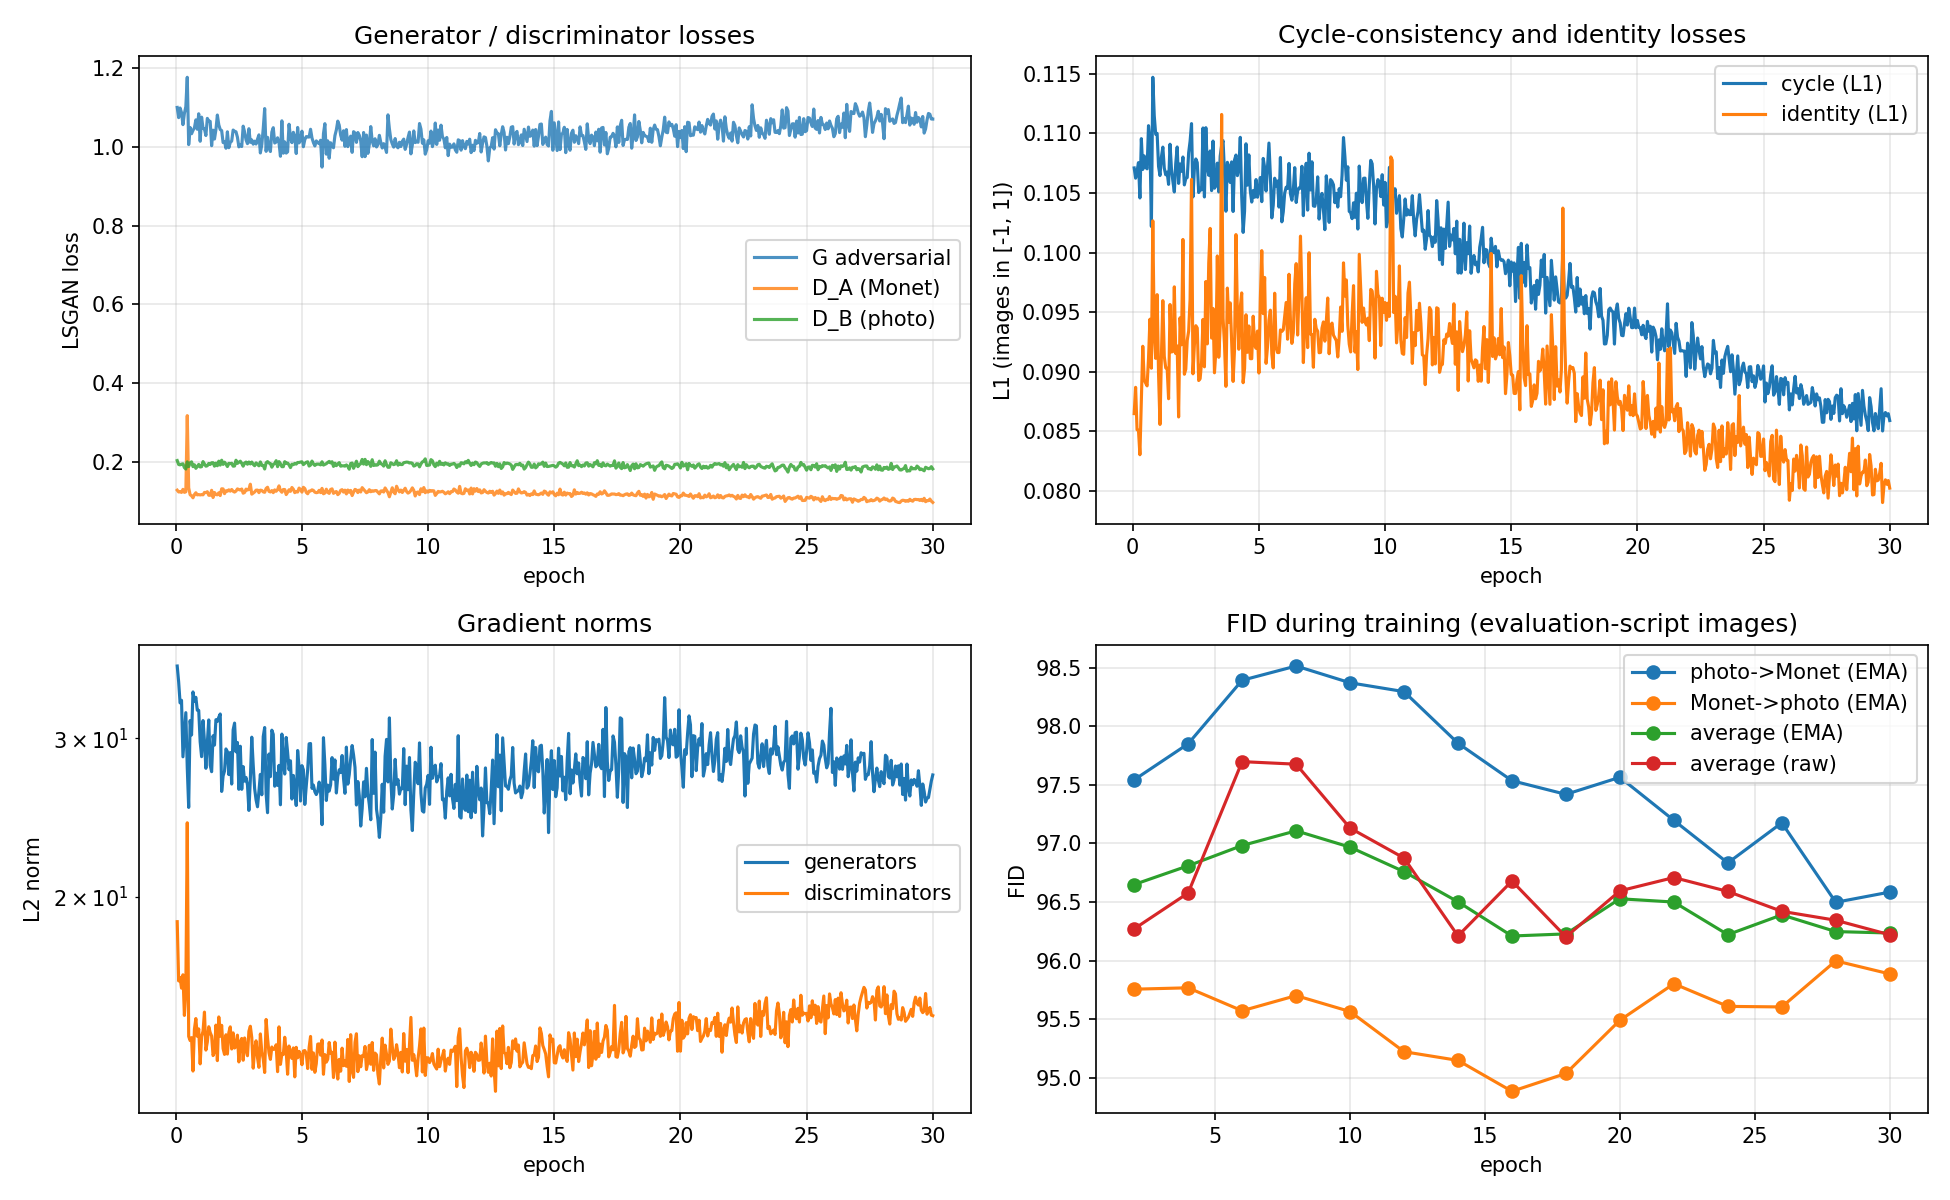

,epoch,iter,fid_B2A_raw,mifid_B2A_raw,fid_A2B_raw,mifid_A2B_raw,FID_raw,MiFID_raw,score_raw,fid_B2A_ema,mifid_B2A_ema,fid_A2B_ema,mifid_A2B_ema,FID_ema,MiFID_ema,score_ema
0,2,3520,96.556587,0.407275,95.985396,0.416610,96.270991,0.411942,48.341467,97.542897,0.408828,95.755930,0.414186,96.649413,0.411507,48.530460
1,4,7040,96.243149,0.409032,96.911036,0.415399,96.577093,0.412216,48.494654,97.850571,0.409275,95.767832,0.413302,96.809202,0.411288,48.610245
2,6,10560,97.418902,0.409236,97.977609,0.413932,97.698256,0.411584,49.054920,98.392666,0.410016,95.571884,0.414551,96.982275,0.412283,48.697279
3,8,14080,98.853803,0.408765,96.499229,0.411604,97.676516,0.410184,49.043350,98.514372,0.409220,95.701267,0.415467,97.107819,0.412343,48.760081
4,10,17600,97.805197,0.407762,96.457366,0.416277,97.131281,0.412020,48.771651,98.371296,0.409099,95.565246,0.415537,96.968271,0.412318,48.690294
5,12,21120,97.623356,0.407962,96.127300,0.416137,96.875328,0.412049,48.643689,98.295716,0.409972,95.222563,0.414952,96.759140,0.412462,48.585801
6,14,24640,97.045335,0.409640,95.375819,0.412614,96.210577,0.411127,48.310852,97.855469,0.410190,95.148245,0.415912,96.501857,0.413051,48.457454
7,16,28160,98.102339,0.406529,95.256127,0.415697,96.679233,0.411113,48.545173,97.535666,0.408825,94.884321,0.415311,96.209994,0.412068,48.311031
8,18,31680,97.347152,0.408902,95.058190,0.413832,96.202671,0.411367,48.307019,97.419023,0.408579,95.036720,0.415209,96.227871,0.411894,48.319883
9,20,35200,97.077175,0.407650,96.113363,0.417421,96.595269,0.412536,48.503902,97.564797,0.407891,95.490749,0.415054,96.527773,0.411472,48.469622


Samples (rows: photo | photo->Monet | back to photo, then Monet | Monet->photo | back to Monet): task3_gan/kruthika/outputs/cyclegan_v2_ft/samples/epoch_030.jpg


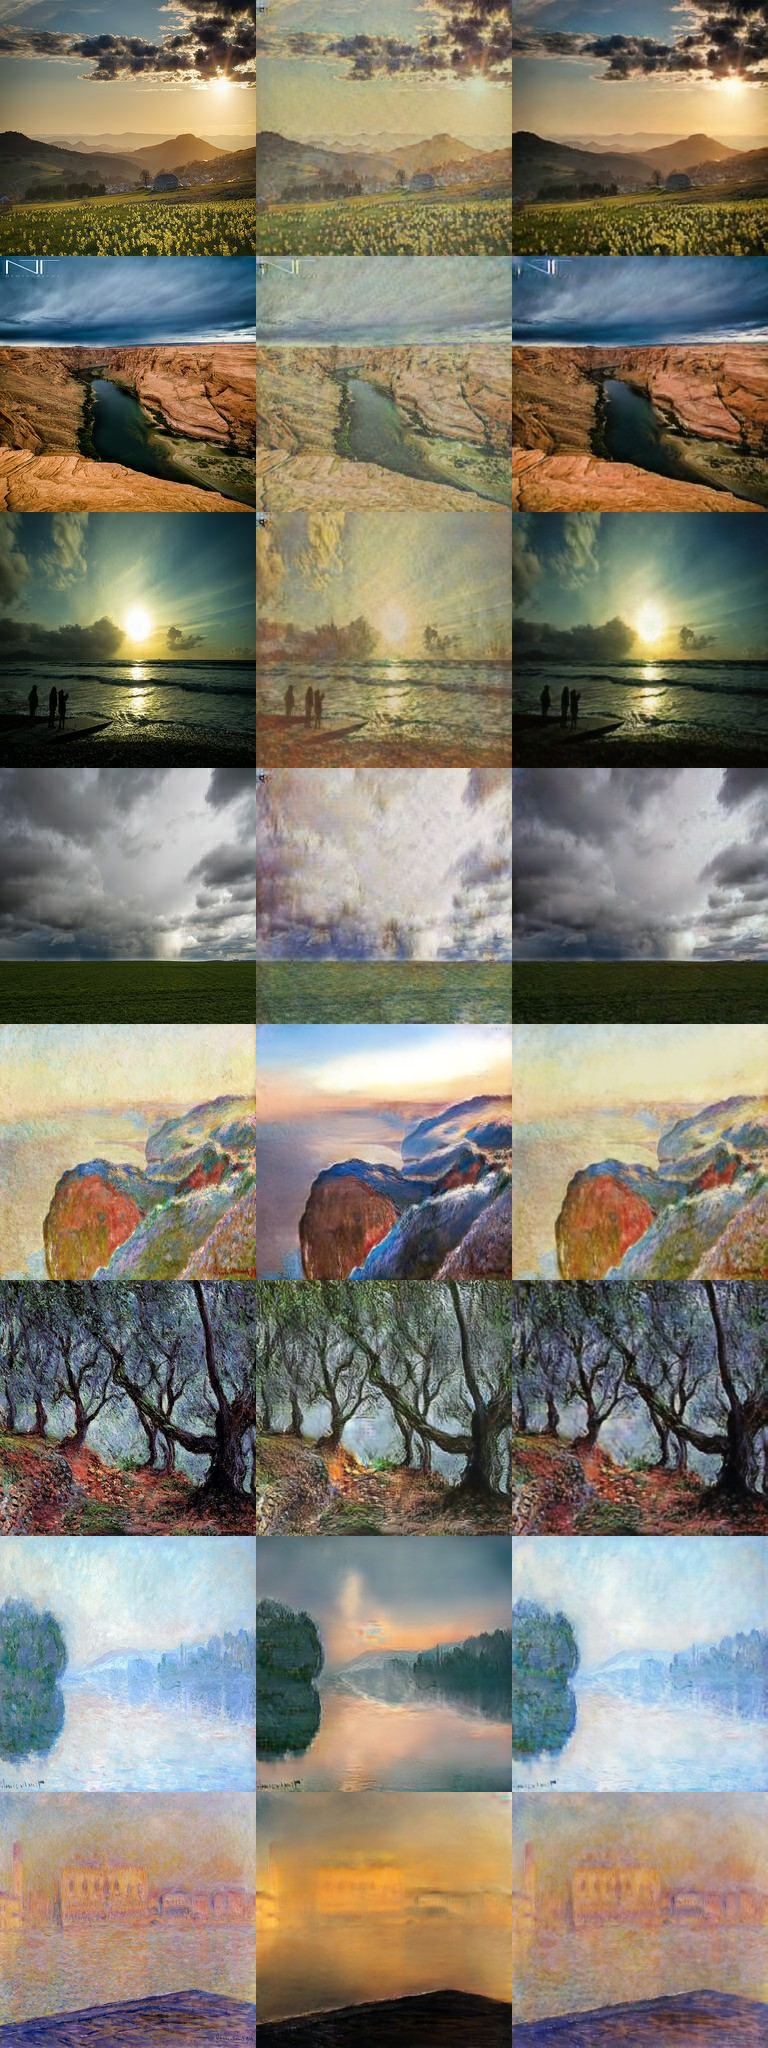

,direction,metric,value
0,photo->monet (B2A),fid_eval_script,97.4402104872012
1,photo->monet (B2A),mifid_eval_script,0.40888740381038063
2,monet->photo (A2B),fid_eval_script,95.10337711887578
3,monet->photo (A2B),mifid_eval_script,0.41406744098688003
4,submission,FID_average,96.27179380303849
5,submission,MiFID_average,0.41147742239863033
6,submission,estimated_leaderboard_score,-48.34163561271856
7,photo->monet (B2A),fid_all_images,80.12153341659933
8,monet->photo (A2B),fid_all_images,77.25836132504669
9,photo->monet (B2A),kid_mean,0.007777329986015746


In [16]:
import json, glob, pandas as pd
from IPython.display import Image, display
OUT = f"task3_gan/kruthika/outputs/{RUN}"
print(open("task3_gan/kruthika/submission.csv").read())
display(Image(f"{OUT}/training_curves.png"))
display(pd.read_csv(f"{OUT}/eval_history.csv"))
last = sorted(glob.glob(f"{OUT}/samples/*.jpg"))[-1]
print("Samples (rows: photo | photo->Monet | back to photo, then Monet | Monet->photo | back to Monet):", last)
display(Image(last, width=600))
pd.set_option("display.max_rows", 200)
pd.read_csv("task3_gan/kruthika/full_metrics_report.csv")

## 9. Submit to Kaggle (optional)
Set `SUBMIT = True` to upload `submission.csv` (5 submissions per day).

In [17]:
SUBMIT = False
MESSAGE = f"{RUN}: CycleGAN, {EPOCHS} epochs"
if SUBMIT:
    !kaggle competitions submit -c data-266-fall-2026-gan-image-style-transfer -f task3_gan/kruthika/submission.csv -m "{MESSAGE}"
    !kaggle competitions submissions -c data-266-fall-2026-gan-image-style-transfer | head -5

## 10. Download results
Zips logs, manifests, metrics, submission.csv, plots, samples, predictions (pred_A2B, pred_B2A), the human-audit
sheet and the best checkpoint (not the dataset or the large resume checkpoint). Unzip into the repo root.

In [18]:
!rm -f task3_results.zip
!zip -qr task3_results.zip reproducibility task3_gan/kruthika -x "*_last.pt" "*__pycache__*" "task3_gan/kruthika/src/*" "task3_gan/kruthika/evaluate_local.py"
!ls -lh task3_results.zip
from google.colab import files
files.download("task3_results.zip")

-rw------- 1 root root 296M Oct  4 05:44 task3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>